# US Treasury yield curve: Nelson-Siegel, PCA and bond portfolio risk

**Objective:** model the US Treasury curve since 1990 with the Nelson-Siegel model, check that three factors (level, slope and curvature) explain almost all the moves of the curve, and use the fitted curve to compare a bullet and a barbell bond portfolio with the same duration.

**Data:** Daily Treasury Par Yield Curve Rates, U.S. Department of the Treasury (home.treasury.gov).

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `requests` and `scipy`.

## Part 1. Libraries

In [1]:
import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from scipy.optimize import least_squares

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## Part 2. Download the curves

The Treasury publishes one CSV per year, so we download them one by one and put them together.

In [2]:
ruta = "data/treasury_par_curve_daily.csv"
if not os.path.exists(ruta):
    anios = []
    for y in range(1990, 2027):
        url = ("https://home.treasury.gov/resource-center/data-chart-center/interest-rates/daily-treasury-rates.csv/"
               f"{y}/all?type=daily_treasury_yield_curve&field_tdr_date_value={y}&page&_format=csv")
        anios.append(pd.read_csv(io.StringIO(requests.get(url, timeout=120).text)))
    pd.concat(anios).to_csv(ruta, index=False)

maturities = {"1 Mo": 1/12, "2 Mo": 2/12, "3 Mo": 0.25, "4 Mo": 4/12, "6 Mo": 0.5, "1 Yr": 1, "2 Yr": 2,
              "3 Yr": 3, "5 Yr": 5, "7 Yr": 7, "10 Yr": 10, "20 Yr": 20, "30 Yr": 30}
curve = pd.read_csv(ruta, parse_dates=["Date"]).set_index("Date").sort_index()
curve = curve[[c for c in maturities if c in curve.columns]].apply(pd.to_numeric, errors="coerce")
print("Days:", len(curve), "| from", curve.index.min().date(), "to", curve.index.max().date())
curve.tail()

Days: 9207 | from 1990-01-02 to 2026-10-20


,1 Mo,2 Mo,3 Mo,4 Mo,6 Mo,1 Yr,2 Yr,3 Yr,5 Yr,7 Yr,10 Yr,20 Yr,30 Yr
Date,,,,,,,,,,,,,
2026-10-14,4.11,4.15,4.28,4.36,4.37,4.53,4.82,4.92,5.00,5.09,5.19,5.57,5.52
2026-10-15,4.17,4.19,4.28,4.35,4.35,4.49,4.77,4.85,4.91,5.00,5.10,5.48,5.43
2026-10-16,4.12,4.17,4.26,4.32,4.34,4.46,4.74,4.82,4.89,4.98,5.09,5.47,5.43
2026-10-19,4.11,4.17,4.27,4.34,4.37,4.50,4.77,4.85,4.94,5.04,5.15,5.53,5.48
2026-10-20,4.10,4.17,4.26,4.34,4.36,4.51,4.79,4.86,4.94,5.02,5.12,5.47,5.42


## Part 3. Nelson-Siegel for every day

We use the Diebold and Li (2006) version: the decay parameter is fixed (lambda = 0.0609 per month, 0.7308 per year), so for each day the three betas come from a simple OLS regression.

- beta0 is the **level** (long-term yield)
- beta1 is the **slope** (negative when the curve goes up)
- beta2 is the **curvature** (hump in the middle)

In [3]:
lam = 0.7308

def loadings(tau):
    x = lam * tau
    f1 = (1 - np.exp(-x)) / x
    f2 = f1 - np.exp(-x)
    return np.column_stack([np.ones_like(tau), f1, f2])

filas = []
for fecha, fila in curve.iterrows():
    fila = fila.dropna()
    if len(fila) < 6:
        continue
    tau = np.array([maturities[c] for c in fila.index])
    X = loadings(tau)
    beta = np.linalg.lstsq(X, fila.values, rcond=None)[0]
    error = X @ beta - fila.values
    filas.append([fecha, beta[0], beta[1], beta[2], np.sqrt(np.mean(error ** 2)) * 100])

ns = pd.DataFrame(filas, columns=["date", "level", "slope", "curvature", "rmse_bp"]).set_index("date")
ns.to_csv("data/ns_factors_daily.csv")
print("Median fitting error:", round(ns["rmse_bp"].median(), 1), "bp")

Median fitting error: 8.4 bp


We check that the factors mean what the theory says, comparing them with simple measures of the curve:

In [4]:
print("level vs 10y yield:", round(ns["level"].corr(curve["10 Yr"]), 3))
print("-slope vs 10y - 3m spread:", round((-ns["slope"]).corr(curve["10 Yr"] - curve["3 Mo"]), 3))
print("curvature vs 2*2y - 3m - 10y:", round(ns["curvature"].corr(2 * curve["2 Yr"] - curve["3 Mo"] - curve["10 Yr"]), 3))

level vs 10y yield: 0.971
-slope vs 10y - 3m spread: 0.995
curvature vs 2*2y - 3m - 10y: 0.98


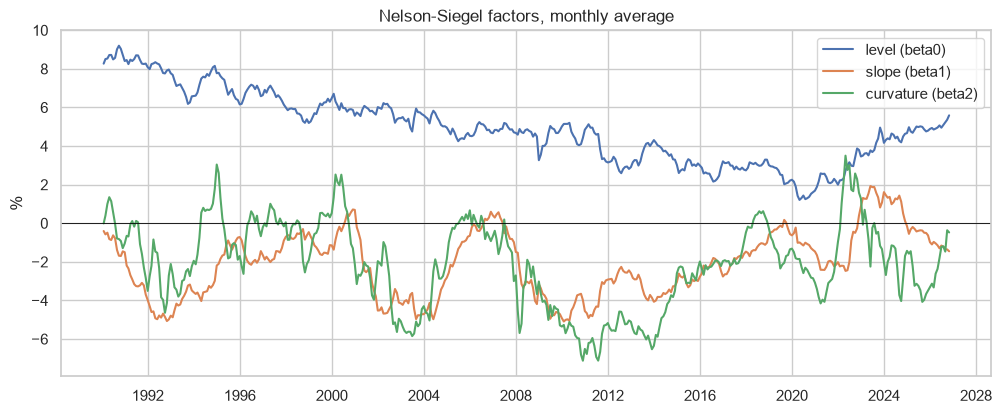

In [5]:
mensual = ns.resample("ME").mean()
plt.figure(figsize=(12, 4.5))
plt.plot(mensual.index, mensual["level"], label="level (beta0)")
plt.plot(mensual.index, mensual["slope"], label="slope (beta1)")
plt.plot(mensual.index, mensual["curvature"], label="curvature (beta2)")
plt.axhline(0, color="black", lw=0.6)
plt.title("Nelson-Siegel factors, monthly average")
plt.ylabel("%")
plt.legend()
plt.savefig("figures/ns_factors.png", bbox_inches="tight")
plt.show()

## Part 4. Nelson-Siegel-Svensson on the latest curve

For the latest day we fit the complete Svensson model (6 parameters, two humps) with non-linear least squares.

In [6]:
ultimo = curve.dropna(thresh=10).iloc[-1].dropna()
tau = np.array([maturities[c] for c in ultimo.index])

def svensson(p, t):
    b0, b1, b2, b3, l1, l2 = p
    g1 = (1 - np.exp(-t / l1)) / (t / l1)
    g2 = (1 - np.exp(-t / l2)) / (t / l2)
    return b0 + b1 * g1 + b2 * (g1 - np.exp(-t / l1)) + b3 * (g2 - np.exp(-t / l2))

res = least_squares(lambda p: svensson(p, tau) - ultimo.values, x0=[4.5, -0.5, 0.5, 0.5, 1.5, 10],
                    bounds=([0, -10, -20, -20, 0.05, 2], [15, 10, 20, 20, 5, 30]))
beta_hoy = np.linalg.lstsq(loadings(tau), ultimo.values, rcond=None)[0]
print("Date:", ultimo.name.date())
print("Svensson parameters:", np.round(res.x, 3))
print("Svensson error:", round(np.sqrt(np.mean(res.fun ** 2)) * 100, 2), "bp")
print("Nelson-Siegel level, slope, curvature:", np.round(beta_hoy, 2))

Date: 2026-10-20
Svensson parameters: [ 1.316  2.767  3.806 12.38   1.894 15.834]
Svensson error: 2.57 bp
Nelson-Siegel level, slope, curvature: [ 5.43 -1.28 -0.23]


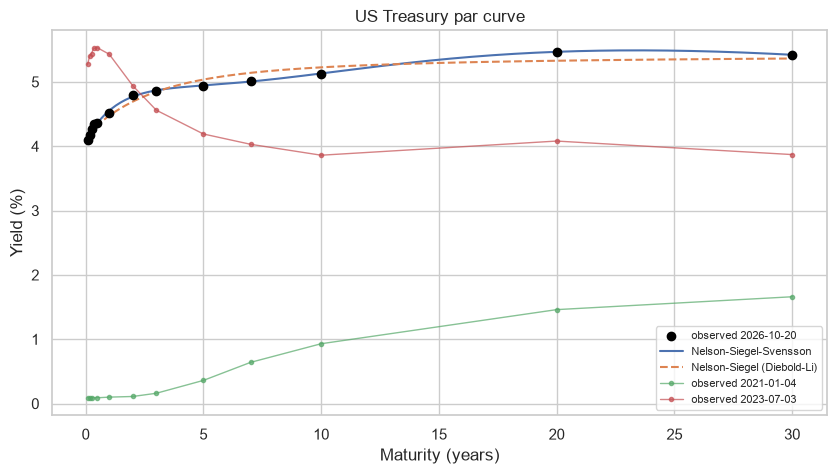

In [7]:
t = np.linspace(1/12, 30, 300)
plt.figure(figsize=(10, 5))
plt.scatter(tau, ultimo.values, color="black", zorder=5, label="observed " + str(ultimo.name.date()))
plt.plot(t, svensson(res.x, t), label="Nelson-Siegel-Svensson")
plt.plot(t, loadings(t) @ beta_hoy, ls="--", label="Nelson-Siegel (Diebold-Li)")
for d in ["2021-01-04", "2023-07-03"]:
    f = curve.loc[d:].iloc[0].dropna()
    plt.plot([maturities[c] for c in f.index], f.values, marker=".", lw=1, alpha=0.7, label="observed " + str(f.name.date()))
plt.title("US Treasury par curve")
plt.xlabel("Maturity (years)")
plt.ylabel("Yield (%)")
plt.legend(fontsize=8)
plt.savefig("figures/curve_fit.png", bbox_inches="tight")
plt.show()

In January 2021 the curve was very steep with short rates at zero, in July 2023 it was inverted (short rates above long rates) and today it has a normal positive slope again.

## Part 5. PCA of the daily changes

We use the daily changes since February 2006 (when the 20 and 30 year bonds are both available).

In [8]:
cols = ["3 Mo", "6 Mo", "1 Yr", "2 Yr", "3 Yr", "5 Yr", "7 Yr", "10 Yr", "20 Yr", "30 Yr"]
cambios = curve.loc["2006-02-09":, cols].diff().dropna()
valores, vectores = np.linalg.eigh(np.cov(cambios.T.values))
orden = valores.argsort()[::-1]
valores, vectores = valores[orden], vectores[:, orden]
explicada = valores / valores.sum()
print("Variance explained by each component:", np.round(explicada[:4], 4))
print("First 3 components:", round(explicada[:3].sum(), 4))

Variance explained by each component: [0.7556 0.137  0.0627 0.0189]
First 3 components: 0.9553


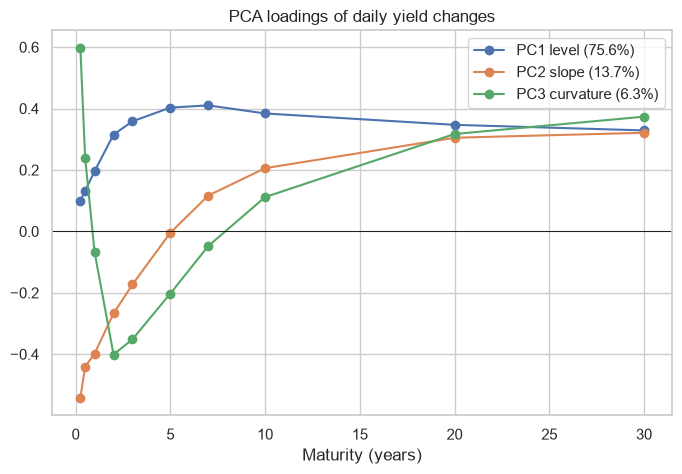

In [9]:
if vectores[:, 0].sum() < 0:
    vectores[:, 0] = -vectores[:, 0]
if vectores[-1, 1] < vectores[0, 1]:
    vectores[:, 1] = -vectores[:, 1]
mats = [maturities[c] for c in cols]
plt.figure(figsize=(8, 5))
for i, nombre in enumerate(["PC1 level", "PC2 slope", "PC3 curvature"]):
    plt.plot(mats, vectores[:, i], marker="o", label=f"{nombre} ({explicada[i]:.1%})")
plt.axhline(0, color="black", lw=0.6)
plt.title("PCA loadings of daily yield changes")
plt.xlabel("Maturity (years)")
plt.legend()
plt.savefig("figures/pca_loadings.png", bbox_inches="tight")
plt.show()

The first component moves all the yields in the same direction (level), the second moves short and long yields in opposite directions (slope) and the third one moves the middle against the extremes (curvature). This is the same structure of the Nelson-Siegel factors.

## Part 6. Bullet vs barbell

We build par bonds with the yields of today's Nelson-Siegel curve. The bullet is 100% in the 5 year bond and the barbell is a mix of the 2 and 30 year bonds with the **same modified duration**. Then we reprice both portfolios under different movements of the curve.

In [10]:
def precio(y, T, c):
    n = int(T * 2)
    t = np.arange(1, n + 1) / 2
    flujos = np.full(n, c / 2 * 100)
    flujos[-1] += 100
    return np.sum(flujos / (1 + y / 2) ** (t * 2))

def yld(T):
    return (loadings(np.array([T])) @ beta_hoy)[0] / 100

bonos = pd.DataFrame(index=[2, 5, 10, 30], columns=["yield", "duration", "convexity"], dtype=float)
h = 0.0001
for T in bonos.index:
    y = yld(T)
    p0, pu, pd_ = precio(y, T, y), precio(y + h, T, y), precio(y - h, T, y)
    bonos.loc[T] = [y * 100, (pd_ - pu) / (2 * h * p0), (pu + pd_ - 2 * p0) / (h ** 2 * p0)]
w30 = (bonos.loc[5, "duration"] - bonos.loc[2, "duration"]) / (bonos.loc[30, "duration"] - bonos.loc[2, "duration"])
print("Barbell weights: 2y =", round(1 - w30, 3), "| 30y =", round(w30, 3))
bonos.round(2)

Barbell weights: 2y = 0.808 | 30y = 0.192


,yield,duration,convexity
2,4.69,1.89,4.56
5,5.04,4.37,22.58
10,5.23,7.71,72.50
30,5.36,14.83,330.53


In [11]:
def retorno(pesos, shock):
    total = 0
    for T, w in pesos.items():
        y = yld(T)
        total += w * (precio(y + shock(T), T, y) / precio(y, T, y) - 1)
    return total * 100

bullet = {5: 1.0}
barbell = {2: 1 - w30, 30: w30}
escenarios = {"parallel +100bp": lambda T: 0.01,
              "parallel -100bp": lambda T: -0.01,
              "bear steepener": lambda T: 0.01 * (T - 2) / 28,
              "bull flattener": lambda T: -0.01 * (T - 2) / 28,
              "butterfly (wings +50, belly -50)": lambda T: 0.005 if T in (2, 30) else -0.005}
tabla = pd.DataFrame({e: [retorno(bullet, s), retorno(barbell, s)] for e, s in escenarios.items()},
                     index=["bullet 5y", "barbell 2y/30y"]).T.round(2)
tabla.to_csv("data/scenario_returns.csv")
tabla

,bullet 5y,barbell 2y/30y
parallel +100bp,-4.26,-4.06
parallel -100bp,4.49,4.74
bear steepener,-0.47,-2.55
bull flattener,0.47,3.19
"butterfly (wings +50, belly -50)",2.21,-2.11


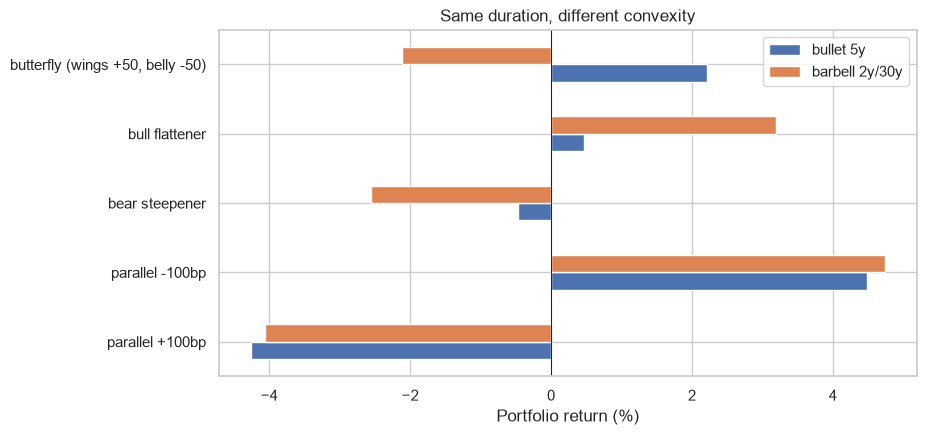

In [12]:
tabla.plot.barh(figsize=(9, 4.5))
plt.axvline(0, color="black", lw=0.6)
plt.title("Same duration, different convexity")
plt.xlabel("Portfolio return (%)")
plt.savefig("figures/bullet_vs_barbell.png", bbox_inches="tight")
plt.show()

## Conclusions

- With a fixed lambda, Nelson-Siegel fits the daily curves with a median error of a few basis points, and the factors behave like the level, the slope and the curvature of the curve.
- The PCA confirms it: three components explain about 95% of the variance of the daily changes, and the first one alone (level) explains around 75%.
- The barbell has more convexity than the bullet, so it wins in both parallel shifts. But it loses when the curve steepens and in the butterfly scenario, where the belly (5y) rallies. Duration alone is not enough to manage the risk of a bond portfolio.